# Pandas: практика и комплексные задачи

Здесь ты будешь **самостоятельно тренироваться по Pandas** на большом наборе Online Retail: 541 909 строк о покупках интернет-магазина. В каждом разделе сначала небольшой кусок теории, затем запущенные примеры с видимыми результатами и **пять задач**. Всего 30 задач: 25 упражнений на Online Retail и 5 комплексных кейсов на отдельных CSV. Задачи не имеют готового кода: попробуй написать его в ячейках под условиями.

**Автопроверка:** после решения каждого задания положи указанный результат в `ans` и запусти `test_task_N(номер, ans)`. Проверка сверяет таблицы и числа. Вопросы «Как думать» и текстовые выводы необязательны; для выполнения задач достаточно кода. Сначала запусти ячейку загрузки данных.

Одна строка набора — **одна товарная позиция в счёте**, а не целый заказ. Когда ищешь закономерность, сначала реши, что сравниваешь: строки, счета, товары или клиентов. Если хочешь, после расчёта обсуди результат и ограничения с преподавателем.

### Оглавление

1. [Данные и как работать](#data)
2. [Таблица, типы, индекс и осмотр → задачи 1–5](#topic6)
3. [Фильтры и новые столбцы → задачи 6–10](#topic7)
4. [Очистка, пропуски и большие значения → задачи 11–15](#topic8)
5. [Группировки, сводные таблицы и графики → задачи 16–20](#topic9)
6. [Соединения и время → задачи 21–25](#topic10)
7. [Плотная шпаргалка](#cheat)
8. [Комплексные задачи 26–30](#complex)

**Алгоритм для любой задачи:** сформулируй вопрос → выбери нужные строки и единицу подсчёта → посчитай → проверь странный результат → сделай осторожный вывод.

<a id="data"></a>
## Данные: запусти ячейку ниже

Она скачает набор с [сайта UCI](https://archive.ics.uci.edu/dataset/352/online-retail). Первый запуск требует интернет и `openpyxl`; потом используется кеш. Источник: Daqing Chen, UCI Machine Learning Repository, 2015, [DOI 10.24432/C5BW33](https://doi.org/10.24432/C5BW33), лицензия [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

**Перед выводами:** одна строка здесь — *один товар в счёте*. Если у счёта пять товаров, в таблице будет пять строк. Число строк не равно числу заказов.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlretrieve
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sys

TESTS_DIR = Path("programming/class11: train pandas")
if TESTS_DIR.is_dir():
    sys.path.insert(0, str(TESTS_DIR.resolve()))
from tests_pandas_practice import test_task_N

DATA_URL = "https://archive.ics.uci.edu/static/public/352/online%2Bretail.zip"
cache_dir = Path("data")
cache_dir.mkdir(exist_ok=True)
zip_path = cache_dir / "online_retail_uci.zip"
csv_path = cache_dir / "online_retail.csv.gz"

if not csv_path.exists():
    if not zip_path.exists():
        print("Скачиваю официальный набор UCI (около 23 МБ)...")
        urlretrieve(DATA_URL, zip_path)
    with ZipFile(zip_path) as archive:
        excel_bytes = BytesIO(archive.read("Online Retail.xlsx"))
    retail = pd.read_excel(excel_bytes, engine="openpyxl",
                           dtype={"InvoiceNo": "string", "StockCode": "string",
                                  "Description": "string", "Country": "string"})
    retail["CustomerID"] = retail["CustomerID"].astype("Int64")
    retail.to_csv(csv_path, index=False, compression="gzip")

retail = pd.read_csv(csv_path, compression="gzip", parse_dates=["InvoiceDate"],
                     dtype={"InvoiceNo": "string", "StockCode": "string",
                            "Description": "string", "CustomerID": "Int64", "Country": "string"},
                     low_memory=False)
print("Pandas:", pd.__version__, "| Размер:", retail.shape)
display(retail.head())

Pandas: 3.1.1 | Размер: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


**Что видим.** 541 909 строк и 8 столбцов. В первых пяти строках несколько раз повторяется счёт `536365`: это разные товары одного счёта.

**Как думать.** Прежде чем считать «заказы», найди единицу строки. Здесь число заказов нужно считать через `InvoiceNo.nunique()`, а не через `len(retail)`.

### Что означают столбцы

| Столбец | Простое объяснение |
|---|---|
| `InvoiceNo` | номер счёта; `C` в начале означает отмену |
| `StockCode` | код товара или служебной позиции |
| `Description` | название позиции; иногда его нет |
| `Quantity` | сколько единиц записано в строке; при отмене бывает отрицательным |
| `UnitPrice` | цена одной единицы в фунтах (£) |
| `InvoiceDate` | дата и время счёта |
| `CustomerID` | номер клиента; у части строк его нет |
| `Country` | страна клиента |

**Первый вопрос:** что считать «продажей»? Строка с отрицательным количеством или нулевой ценой требует отдельной проверки.

<a id="topic6"></a>
## 1. Таблица, типы и осмотр

`DataFrame` — вся таблица, `Series` — один столбец. `retail["Quantity"]` даёт Series, `retail[["Quantity"]]` — таблицу из одного столбца. Пиши название в квадратных скобках: это работает даже при пробелах и совпадении имени с методом Pandas.

Тип столбца важен. Даты должны быть датами, а коды товаров и счетов — строками. `CustomerID` выглядит как число, но его **нельзя усреднять**: номер клиента не обозначает количество. При повторном чтении CSV типы нужно задать снова.

In [2]:
print("Один столбец:", type(retail["Quantity"]).__name__)
print("Таблица из одного столбца:", type(retail[["Quantity"]]).__name__)
display(retail.dtypes.astype(str).rename("dtype"))
print("Строки и столбцы:", retail.shape)
print("Диапазон дат:", retail["InvoiceDate"].min(), "—", retail["InvoiceDate"].max())

Один столбец: Series
Таблица из одного столбца: DataFrame


InvoiceNo              string
StockCode              string
Description            string
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              Int64
Country                string
Name: dtype, dtype: str

Строки и столбцы: (541909, 8)
Диапазон дат: 2010-12-01 08:26:00 — 2011-12-09 12:50:00


**Что видим.** `Quantity` — целые, `UnitPrice` — числа с дробью, дата распознана как дата. Счета и коды товаров хранятся как строки. Последняя запись — 9 декабря 2011 года.

**Как думать.** Проверяй типы сразу после чтения. Если код стал числом, можно потерять ведущие нули или буквы. А декабрь 2011 — неполный месяц: его сумма сама по себе не говорит о падении продаж.

### Индекс и выравнивание

Индекс — подпись строки. Когда соединяешь два столбца, Pandas смотрит на подписи. Если метки есть только в одном столбце, в другой колонке получится `NaN`.

In [3]:
a = retail.loc[0:2, "Quantity"]
b = retail.loc[1:3, "UnitPrice"]
display(pd.concat([a.rename("Quantity"), b.rename("UnitPrice")], axis=1))

,Quantity,UnitPrice
0,6.0,NaN
1,6.0,3.39
2,8.0,2.75
3,NaN,3.39


**Что видим.** На метке 0 нет цены из `b`, а на метке 3 нет количества из `a`. Это результат выравнивания по индексу.

**Как думать.** Если после объединения появились пустые клетки, проверь совпадение меток. Не считай `NaN` нулём автоматически.

### Быстрый осмотр незнакомой таблицы

Сначала спроси: сколько строк и столбцов? Где пропуски? Есть ли одинаковые строки? Какие значения самые маленькие и большие? Для этого хватит `shape`, `dtypes`, `isna().sum()`, `duplicated().sum()`, `nunique()` и `describe()`.

`axis=0` даёт результат **для каждого столбца**, `axis=1` — **для каждой строки**. Но команду можно выполнить и над бессмысленными величинами: сложить штуки и фунты технически возможно, анализу это не поможет.

In [4]:
audit = pd.DataFrame({
    "dtype": retail.dtypes.astype(str),
    "missing": retail.isna().sum(),
    "missing_share": retail.isna().mean().round(3),
    "unique": retail.nunique(),
})
display(audit)
print("Полных дублей:", int(retail.duplicated().sum()))
display(retail[["Quantity", "UnitPrice"]].describe().round(2))
print("Сумма по двум числовым столбцам:")
display(retail[["Quantity", "UnitPrice"]].head(4).sum(axis=0))
print("Сумма по строкам:")
display(retail[["Quantity", "UnitPrice"]].head(4).sum(axis=1))

,dtype,missing,missing_share,unique
InvoiceNo,string,0,0.000,25900
StockCode,string,0,0.000,4070
Description,string,1454,0.003,4223
Quantity,int64,0,0.000,722
InvoiceDate,datetime64[us],0,0.000,23260
UnitPrice,float64,0,0.000,1630
CustomerID,Int64,135080,0.249,4372
Country,string,0,0.000,38


Полных дублей: 5268


,Quantity,UnitPrice
count,541909.00,541909.00
mean,9.55,4.61
std,218.08,96.76
min,-80995.00,-11062.06
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,80995.00,38970.00


Сумма по двум числовым столбцам:


Quantity     26.00
UnitPrice    12.08
dtype: float64

Сумма по строкам:


0     8.55
1     9.39
2    10.75
3     9.39
dtype: float64

**Что видим.** `CustomerID` пуст в 135 080 строках — примерно в каждой четвёртой. Есть 5 268 полных повторов. Минимальное `Quantity` отрицательно, а максимумы количества и цены намного больше медиан.

**Как думать.** План следующий: отдельно проверить отмены, повторы и большие значения. Число `Quantity + UnitPrice` для строки получается, но не имеет смысла: нельзя складывать штуки и фунты. Каждая метрика должна отвечать на вопрос и иметь единицу измерения.

### Самые простые графики

График строится прямо от столбца или таблицы. `series.plot.line()` показывает изменение по порядку, `.plot.hist(bins=30)` — распределение чисел. `plt.show()` выводит рисунок. Всегда подпиши, **что и в каких единицах** показано. Для дат сначала посчитай значение по месяцам; неполный последний месяц не сравнивай с полным.

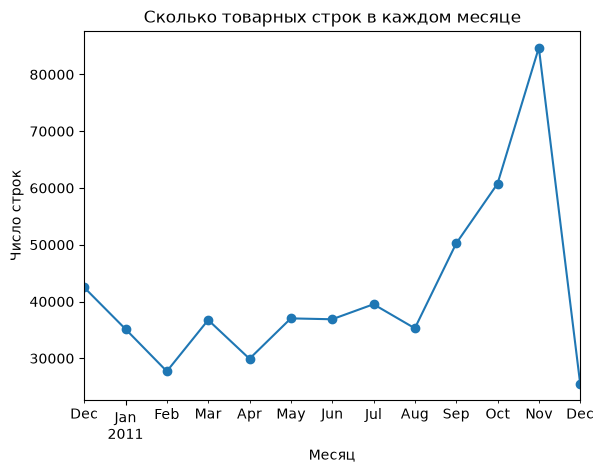

Последняя дата в наборе: 2011-12-09 12:50:00


In [5]:
monthly_lines = (retail["InvoiceDate"].dt.to_period("M")
                 .value_counts().sort_index())
monthly_lines.plot.line(title="Сколько товарных строк в каждом месяце",
                        xlabel="Месяц", ylabel="Число строк", marker="o")
plt.show()
print("Последняя дата в наборе:", retail["InvoiceDate"].max())

**Что видим.** В декабре 2011 число строк резко меньше. Но файл заканчивается 9 декабря.

**Как думать.** Сначала проверь полноту периода. Эти данные не доказывают падение продаж за весь декабрь.

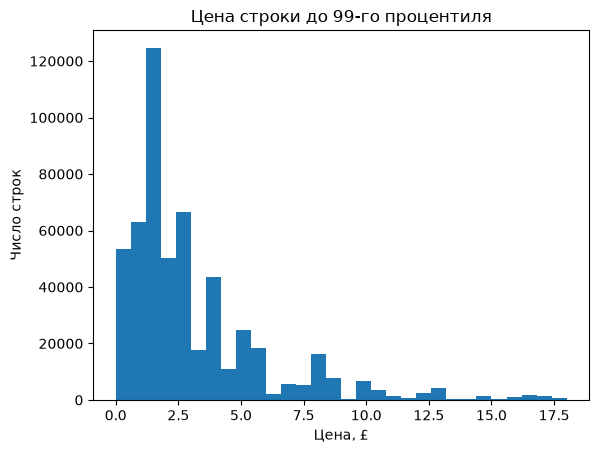

Для читаемости не показаны строки выше £ 18.0


In [6]:
limit = retail["UnitPrice"].quantile(.99)
retail.loc[retail["UnitPrice"].between(0, limit), "UnitPrice"].plot.hist(
    bins=30, title="Цена строки до 99-го процентиля", xlabel="Цена, £", ylabel="Число строк")
plt.show()
print("Для читаемости не показаны строки выше £", round(limit, 2))

**Что видим.** У большинства строк цена ниже верхнего 1% значений. Несколько больших цен растянули бы ось.

**Как думать.** Ограничение сделано только для рисунка. Перед удалением крупных строк из расчётов открой их и выясни, что это.

<a id="tasks6"></a>
### Попробуй сам: 5 задач по осмотру таблицы

### 1.1. Паспорт набора

Сделай «паспорт» `retail`: размер, типы столбцов, число и доля пропусков, точные повторы, число разных значений. Удобно вернуть это из функции `audit(frame)`. **Проверка:** 541 909 строк, 8 столбцов, 5 268 точных повторов.

**Необязательно — подумай:** какой столбец выглядит числовым, но его среднее бессмысленно? Назови две проверки, которые сделаешь следующими, и почему.

In [ ]:
# 1.1. Паспорт набора
# Для автопроверки в ans положите словарь: rows, columns, duplicates и audit (DataFrame с индексом-столбцами retail; dtype, missing, missing_share, unique).
ans = None  # замените на вычисленный результат
test_task_N(1, ans)


### 1.2. Дата и полнота периода

Найди первую и последнюю дату. Посчитай число строк по месяцам через `.dt.to_period("M").value_counts().sort_index()` и построй линию. Выбери два полных месяца и сравни их; декабрь 2011 отметь отдельно.

**Необязательно — подумай:** если последний месяц ниже предыдущего, это точно спад? Напиши вывод, в котором факт отделён от догадки.

In [ ]:
# 1.2. Дата и полнота периода
# Для автопроверки в ans положите словарь: first_date, last_date (Timestamp), monthly_lines (Series: индекс YYYY-MM, число строк).
ans = None  # замените на вычисленный результат
test_task_N(2, ans)


### 1.3. Типы и идентификаторы

Прочитай первые 10 000 строк из `csv_path` через `pd.read_csv(csv_path, nrows=10000)` без указания типов. Сравни распознанные типы с `retail`. Найди код товара, похожий на число.

**Необязательно — подумай:** почему код лучше хранить как текст, даже если он состоит из цифр? Почему расстояние между двумя номерами клиентов ничего не говорит об их похожести?

In [ ]:
# 1.3. Типы и идентификаторы
# Для автопроверки в ans положите словарь: sample_types и retail_types (Series из строк с именами типов, индекс — названия столбцов).
ans = None  # замените на вычисленный результат
test_task_N(3, ans)


### 1.4. Распределения и масштаб

Посмотри медиану, 99-й и 99,9-й процентили `Quantity` и `UnitPrice`. Построй гистограммы до 99-го процентиля, не меняя исходные данные.

**Необязательно — подумай:** сколько строк не попало на рисунок? Что можно сказать об обычных значениях? Какие большие строки стоит открыть отдельно, прежде чем назвать их ошибкой?

In [ ]:
# 1.4. Распределения и масштаб
# Для автопроверки в ans положите DataFrame с индексом Quantity, UnitPrice; столбцы median, p99, p999, omitted_above_p99.
ans = None  # замените на вычисленный результат
test_task_N(4, ans)


### 1.5. Индексы и оси

На первых 20 строках посчитай суммы `Quantity` и `UnitPrice` по столбцам (`axis=0`) и по строкам (`axis=1`). Сравни длину результатов. Затем выбери два коротких столбца с **разными индексами** и соедини их через `pd.concat(..., axis=1)`.

**Необязательно — подумай:** откуда появились `NaN` после соединения? Есть ли смысл складывать количество штук с ценой в фунтах, хотя Pandas это умеет?

In [ ]:
# 1.5. Индексы и оси
# Для автопроверки в ans положите словарь: column_sums и row_sums для первых 20 строк; joined = concat(retail.loc[0:2, "Quantity"], retail.loc[1:3, "UnitPrice"]) по столбцам.
ans = None  # замените на вычисленный результат
test_task_N(5, ans)


<a id="topic7"></a>
## 2. Выбор строк и столбцов

`.loc` выбирает по **подписи строки**, `.iloc` — по **месту в таблице**. После фильтра старые подписи сохраняются. Чтобы получить новые подписи 0, 1, 2, ... используй `reset_index(drop=True)`.

Условий может быть несколько: `(условие_1) & (условие_2)`. Для «или» — `|`, для отрицания — `~`. Если в столбце есть пропуски, сначала подумай, куда их отнести: к «да», «нет» или отдельной группе.

In [12]:
nl = retail.loc[retail["Country"].eq("Netherlands"),
                ["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "Country"]]
print("Строк Нидерландов:", len(nl), "| первые метки:", nl.index[:5].tolist())
print("Первая по позиции:")
display(nl.iloc[[0]])
try:
    nl.loc[0]
except KeyError:
    print("nl.loc[0] → KeyError: метки 0 в этом срезе нет")
print("После сброса индекса:")
display(nl.reset_index(drop=True).head(3))

cancel_mask = retail["InvoiceNo"].str.startswith("C", na=False)
print("Отмены по префиксу C:", int(cancel_mask.sum()))
print("Неположительная цена:", int(retail["UnitPrice"].le(0).sum()))

Строк Нидерландов: 2371 | первые метки: [385, 386, 37952, 37953, 37954]
Первая по позиции:


,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Country
385,536403,2010-12-01 11:27:00,96,1.85,Netherlands


nl.loc[0] → KeyError: метки 0 в этом срезе нет
После сброса индекса:


,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Country
0,536403,2010-12-01 11:27:00,96,1.85,Netherlands
1,536403,2010-12-01 11:27:00,1,15.00,Netherlands
2,539491,2010-12-20 10:09:00,12,0.29,Netherlands


Отмены по префиксу C: 9288
Неположительная цена: 2517


**Что видим.** После фильтра подписи строк сохраняют старые номера. `iloc[0]` берёт первую строку нового среза, `loc[0]` может не найти строку с подписью 0. В файле 9 288 строк с префиксом отмены и 2 517 строк с неположительной ценой.

**Как думать.** Перед выбором строки уточни: нужен её порядковый номер или старая метка? При проверке качества не складывай числа разных проблем без проверки пересечений: одна строка может отвечать нескольким условиям.

### Добавление признаков и правка строк

Работай с копией: `work = retail.copy()`. Новый столбец можно посчитать сразу для всех строк: `Quantity * UnitPrice`. Если меняешь только часть строк, используй `work.loc[маска, "столбец"] = значение`. Несколько вариантов удобно записать через `np.select`.

**Смысл важнее команды:** до вычисления выручки нужно решить, какие строки похожи на продажи, а какие — на отмены или служебные записи.

In [13]:
cancel_mask = retail["InvoiceNo"].str.startswith("C", na=False)
sample = pd.concat([
    retail.head(2),
    retail.loc[cancel_mask].head(2),
    retail.loc[retail["UnitPrice"].le(0)].head(2),
]).copy()
sample["line_value"] = sample["Quantity"] * sample["UnitPrice"]
sample["kind"] = np.select(
    [sample["InvoiceNo"].str.startswith("C", na=False), sample["Quantity"].le(0)],
    ["cancel", "nonpositive_quantity"], default="candidate_sale"
)
sample.loc[sample["UnitPrice"].le(0), "kind"] = "nonpositive_price"
display(sample[["InvoiceNo", "Quantity", "UnitPrice", "line_value", "kind"]])

,InvoiceNo,Quantity,UnitPrice,line_value,kind
0,536365,6,2.55,15.30,candidate_sale
1,536365,6,3.39,20.34,candidate_sale
141,C536379,-1,27.50,-27.50,cancel
154,C536383,-1,4.65,-4.65,cancel
622,536414,56,0.00,0.00,nonpositive_price
1970,536545,1,0.00,0.00,nonpositive_price


**Что видим.** У выбранных строк получились разные пометки: обычная положительная строка, отмена и неположительная цена. `line_value` — количество × цена именно этой строки.

**Как думать.** Сначала запиши правила и их порядок. Если строка подходит сразу под два правила, реши, какое важнее. Затем посчитай частоты пометок на **всей** таблице: маленький пример нужен для проверки кода, а не для общего вывода.

**Приём для задач.** Для условий создай маску из `True`/`False`, например `retail["Country"].eq("France")`. Её среднее — доля строк, для которых условие верно. Если нужно несколько условий, заключай каждое в скобки.

### Попробуй сам: 5 задач по фильтрам и новым столбцам

### 2.1. Три типа строк

Раздели все строки на три непересекающиеся части: отмены, положительные строки с ценой больше нуля и остальные. Проверь, что вместе получилось 541 909 строк. Для каждой части посчитай число строк и сумму `Quantity * UnitPrice`.

**Необязательно — подумай:** какие условия могут пересекаться? Почему отрицательная сумма отмен ещё не говорит, какую сумму нужно вычесть из продаж?

In [ ]:
# 2.1. Три типа строк
# Для автопроверки в ans положите DataFrame: индекс kind = cancel, other, positive_sale; столбцы lines и value (сумма Quantity * UnitPrice). Отмена имеет приоритет.
ans = None  # замените на вычисленный результат
test_task_N(6, ans)


### 2.2. Кто скрывается за пропуском

Сравни строки с известным и неизвестным `CustomerID`: сколько их и какая доля строк без ID? Отдельно найди долю пропусков для Великобритании, Нидерландов и Ирландии (`EIRE`) через маски и `.mean()`. Сравни два выбранных месяца.

**Необязательно — подумай:** одинаково ли часто теряется ID в разных срезах? Что будет неверно, если всем пропускам поставить 0? Какие вопросы можно исследовать и без ID?

In [ ]:
# 2.2. Кто скрывается за пропуском
# Для автопроверки в ans положите словарь: known_lines, unknown_lines, unknown_share; country_missing_share (Series для United Kingdom, Netherlands, EIRE); month_missing_share (Series для 2011-06, 2011-11).
ans = None  # замените на вычисленный результат
test_task_N(7, ans)


### 2.3. Метки против позиций

Отбери две страны и цену выше £10. Не сбрасывая индекс, сравни `.iloc[0]`, `.loc[0]` и `.loc[первая_метка]`. Затем сбрось индекс и повтори.

**Необязательно — подумай:** что меняется — сами строки или только их подписи? Как выбрать первую строку после фильтра без риска `KeyError`?

In [ ]:
# 2.3. Метки против позиций
# Для автопроверки в ans положите словарь: first_label, first_five (DataFrame с исходным индексом), reset_first_five (после reset_index(drop=True)); страны United Kingdom/Netherlands, цена > 10, столбцы InvoiceNo/Country/UnitPrice.
ans = None  # замените на вычисленный результат
test_task_N(8, ans)


### 2.4. Флаг качества

На копии таблицы пометь каждую строку как `cancel`, `nonpositive_quantity`, `nonpositive_price` или `positive_sale`. Заранее задай порядок правил. Сделай один вариант с `np.select`, другой с `.loc`; сравни пометки и посчитай их частоты.

**Необязательно — подумай:** одна строка может подходить под два условия. Какое правило сработает? Почему сумма частот *отдельных условий* может быть больше числа строк?

In [ ]:
# 2.4. Флаг качества
# Для автопроверки в ans положите Series kind длиной retail: приоритет cancel → nonpositive_quantity → nonpositive_price → positive_sale; индекс как у retail.
ans = None  # замените на вычисленный результат
test_task_N(9, ans)


### 2.5. Товарная строка и счёт

Найди 10 отдельных положительных строк с наибольшим `Quantity * UnitPrice`. Посмотри их номера счетов. Выбери один из счетов, открой **все его строки** и посчитай кодом общую сумму счёта. Сравни её с суммой самой крупной строки.

**Необязательно — подумай:** почему самый крупный счёт не обязан содержать самую крупную строку? Как позже найти лидирующие счета сразу для всей таблицы?

In [ ]:
# 2.5. Топ счетов, а не строк
# Для автопроверки в ans положите DataFrame: 10 крупнейших положительных строк retail по Revenue, столбцы InvoiceNo, StockCode, Quantity, UnitPrice, Revenue; исходные индексы.
ans = None  # замените на вычисленный результат
test_task_N(10, ans)


<a id="topic8"></a>
## 3. Очистка данных

Не переписывай исходный `retail`: он нужен для проверки. Создадим `sales` — строки без точных дублей, отмен, неположительного количества и неположительной цены. В новом столбце `Revenue = Quantity * UnitPrice` будет сумма **одной товарной строки**.

Это удобный срез для первых вопросов о продажах. Он **не учитывает возвраты как отдельную чистую выручку** и не является прибылью.

In [19]:
base = retail.drop_duplicates().copy()
sales = base.loc[
    (~base["InvoiceNo"].str.startswith("C", na=False))
    & base["Quantity"].gt(0)
    & base["UnitPrice"].gt(0)
].copy()
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]
print("Сырые строки:", len(retail), "| после удаления дублей:", len(base),
      "| положительные строки продаж:", len(sales))
print("Сумма положительных строк, £:", round(sales["Revenue"].sum(), 2))
print("Известных клиентов:", sales["CustomerID"].nunique())
display(sales.head(3))

Сырые строки: 541909 | после удаления дублей: 536641 | положительные строки продаж: 524878
Сумма положительных строк, £: 10642110.8
Известных клиентов: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00


**Что видим.** После удаления точных повторов осталось 536 641 строка, после выбора положительных строк — 524 878. Их сумма — около £10,64 млн. Известны номера 4 338 клиентов.

**Как думать.** Всегда называй срез, на котором посчитана сумма. Это сумма выбранных положительных строк, а не прибыль и не итог после возвратов. Число известных клиентов не равно числу **всех** покупателей: часть ID отсутствует.

### Пропуски, повторы, текст и даты

Пропуск означает «мы не знаем», а не ноль. Если `CustomerID` пуст, нельзя придумать клиенту номер 0: так мы склеим разных неизвестных людей в одного. `dropna(subset=[...])` удаляет строки только тогда, когда поле необходимо именно для текущего вопроса.

`duplicated()` ищет полные повторы. `.str.contains(..., na=False)` ищет текст, даже если часть названий пустая. Через `.dt.hour`, `.dt.day_of_week`, `.dt.month` можно изучать время.

**Для будущей модели:** если заполняешь пропуски медианой, посчитай её только на обучающей части. Иначе информация из теста попадёт в обучение.

In [20]:
print("Пропуски сырых данных:")
display(retail.isna().sum().rename("missing"))
print("Пример строкового поиска:")
display(sales.loc[sales["Description"].str.contains("CAKESTAND", case=False, na=False),
                  ["StockCode", "Description"]].drop_duplicates().head(5))
print("Час и день недели первого счёта:",
      int(retail["InvoiceDate"].dt.hour.iloc[0]),
      int(retail["InvoiceDate"].dt.day_of_week.iloc[0]))

Пропуски сырых данных:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Name: missing, dtype: int64

Пример строкового поиска:


,StockCode,Description
880,22423,REGENCY CAKESTAND 3 TIER
1030,22776,SWEETHEART CAKESTAND 3 TIER
3414,22776,"CAKESTAND, 3 TIER, LOVEHEART"


Час и день недели первого счёта: 8 2


**Что видим.** У 1 454 строк нет названия товара, у 135 080 — номера клиента. Код `22776` встречается с разными названиями.

**Как думать.** Не заполняй пропуски одним правилом для всех столбцов. Для анализа клиентов строки без ID придётся отделить; для анализа общей суммы они могут пригодиться. Прежде чем делать справочник код → название, проверь, бывает ли у кода несколько названий.

### Большие значения: ошибка или интересный случай?

Правило IQR помечает значения выше $Q_3+1.5\,IQR$ или ниже $Q_1-1.5\,IQR$, где $IQR=Q_3-Q_1$. Это **список для проверки**, а не список для удаления. В магазине большой счёт может быть оптовой покупкой, а высокая цена — служебной записью. Смотри сами строки и название позиции.

In [21]:
q1, q3 = sales["Revenue"].quantile([.25, .75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print("Медиана строки, £:", round(sales["Revenue"].median(), 2))
print("Верхняя IQR-граница, £:", round(upper, 2))
print("Строк выше границы:", int(sales["Revenue"].gt(upper).sum()))
display(sales.nlargest(5, "Revenue")[["InvoiceNo", "Description", "Quantity", "UnitPrice", "Revenue"]])

Медиана строки, £: 9.92
Верхняя IQR-граница, £: 38.4
Строк выше границы: 42624


,InvoiceNo,Description,Quantity,UnitPrice,Revenue
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60
222680,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00
15017,537632,AMAZON FEE,1,13541.33,13541.33
299982,A563185,Adjust bad debt,1,11062.06,11062.06


**Что видим.** Обычная строка по медиане — £9,92. IQR-граница равна £38,40, выше неё 42 624 строки. В топе есть и крупные партии, и `AMAZON FEE`, и `Adjust bad debt`.

**Как думать.** Метка «выброс» означает «посмотри внимательнее». Удаление всех 42 тысяч строк изменило бы ответ. Проверь названия, количество, цену и долю таких строк в общей сумме; раздели товары и служебные позиции, если вопрос именно о товарах.

### Заполнение пропусков: только если это уместно

`fillna` заменяет пустые значения, `dropna(subset=[...])` убирает строки с пустотой в нужном поле. Сначала спроси, **что означает пропуск**. Для `CustomerID` безопаснее оставить неизвестное значение: один код `0` ложно объединил бы разных покупателей. Для числового признака в задаче предсказания иногда берут медиану **только по обучающим данным**.

In [22]:
print("Всего строк без CustomerID:", retail["CustomerID"].isna().sum())
known_customers = sales.dropna(subset=["CustomerID"])
print("Положительных строк с известным клиентом:", len(known_customers))
print("Сумма всех положительных строк, £:", round(sales["Revenue"].sum(), 2))
print("Сумма строк с известным клиентом, £:", round(known_customers["Revenue"].sum(), 2))

Всего строк без CustomerID: 135080
Положительных строк с известным клиентом: 392692
Сумма всех положительных строк, £: 10642110.8
Сумма строк с известным клиентом, £: 8887208.89


**Что видим.** Если удалить строки без клиента, поменяются и число строк, и сумма. Этот срез годится для анализа известных клиентов, но не описывает все продажи.

**Как думать.** У каждого правила очистки есть цена. Считай, сколько строк и какой суммы оно касается.

### Попробуй сам: 5 задач по очистке

### 3.1. Цена правил очистки

Покажи таблицу этапов очистки: сырые строки → без точных повторов → без отмен → положительное количество → положительная цена. На каждом шаге посчитай строки и сумму `Quantity * UnitPrice`.

**Необязательно — подумай:** какое правило изменило ответ сильнее всего? Почему итог нельзя назвать прибылью? Какие возвраты и расходы в нём ещё не разобраны?

In [ ]:
# 3.1. Цена правил очистки
# Для автопроверки в ans положите DataFrame: индекс raw, deduplicated, without_cancel, positive_quantity, positive_price; столбцы rows, value.
ans = None  # замените на вычисленный результат
test_task_N(11, ans)


### 3.2. Дубли и единица наблюдения

Найди точные повторы. Сравни их число в двух странах и двух месяцах **через фильтры**, затем посчитай, как меняется сумма положительных строк после удаления дублей. Открой несколько повторяющихся строк.

**Необязательно — подумай:** почему одинаковый `StockCode` в одном счёте ещё не означает точный повтор? Какие столбцы должны совпасть для полного дубля?

In [ ]:
# 3.2. Дубли и единица наблюдения
# Для автопроверки в ans положите словарь: duplicate_lines, country_duplicates (Series для United Kingdom, Netherlands), month_duplicates (Series для 2011-06, 2011-11), revenue_removed.
ans = None  # замените на вычисленный результат
test_task_N(12, ans)


### 3.3. Пропуски описаний

Найди строки без `Description`. Сравни долю пустых названий среди отмен и обычных положительных строк. Посмотри все непустые названия для кода `22776` и проверь, одинаковы ли они.

**Необязательно — подумай:** можно ли всегда восстановить пустое название по коду? Что делать с кодом, у которого названий несколько?

In [ ]:
# 3.3. Пропуски описаний
# Для автопроверки в ans положите словарь: missing_lines, cancel_missing_share, sale_missing_share, names_22776 (отсортированный список разных непустых названий).
ans = None  # замените на вычисленный результат
test_task_N(13, ans)


### 3.4. Выбросы с контекстом

Для суммы строки `Revenue` сравни границу IQR и 99-й процентиль. Посчитай число крупных строк и их долю в общей сумме; открой топ-10. Нарисуй гистограмму и «ящик» для читаемого среза.

**Необязательно — подумай:** это товары, услуги или исправления учёта? Почему удаление всех крупных строк может исказить ответ сильнее, чем их сохранение?

In [ ]:
# 3.4. Выбросы с контекстом
# Для автопроверки в ans положите словарь: iqr_upper, p99, above_iqr, above_p99, above_iqr_share; расчёт на sales.
ans = None  # замените на вычисленный результат
test_task_N(14, ans)


### 3.5. Отмены и возвраты

Сравни строки с `C` в начале `InvoiceNo` и строки с отрицательным `Quantity`: сколько в каждой группе и в пересечении? Для одного товара покажи положительные и отрицательные строки по времени.

**Необязательно — подумай:** можно ли по этим полям точно найти исходную покупку для каждого возврата? Какую информацию для этого хотелось бы иметь?

In [ ]:
# 3.5. Отмены и возвраты
# Для автопроверки в ans положите словарь: cancel_lines, negative_lines, intersection; расчёт на retail.
ans = None  # замените на вычисленный результат
test_task_N(15, ans)


<a id="topic9"></a>
## 4. Группировки и сводки

`groupby("Country")` собирает строки одной страны вместе. Затем можно узнать число строк, число **разных счетов**, сумму или среднее. `agg` даёт одну строку на группу. `transform` возвращает число для каждой исходной строки — так удобно добавлять признаки.

Для сравнения групп всегда выбирай **одинаковую меру**: сумму, число счетов или сумму на один счёт. Большая сумма страны может возникнуть просто потому, что счетов больше.

In [28]:
country = (sales.groupby("Country", as_index=False)
           .agg(lines=("InvoiceNo", "size"), orders=("InvoiceNo", "nunique"),
                revenue=("Revenue", "sum")))
country["share"] = country["revenue"] / country["revenue"].sum()
country = country.sort_values("revenue", ascending=False).reset_index(drop=True)
display(country.head(8).round(3))
print("Доля Великобритании:", round(country.loc[0, "share"], 3))

,Country,lines,orders,revenue,share
0,United Kingdom,479985,18019,9001744.094,0.846
1,Netherlands,2359,94,285446.340,0.027
2,EIRE,7879,288,283140.520,0.027
3,Germany,9025,457,228678.400,0.021
4,France,8392,392,209625.370,0.020
5,Australia,1181,57,138453.810,0.013
6,Spain,2479,90,61558.560,0.006
7,Switzerland,1958,54,57067.600,0.005


Доля Великобритании: 0.846


**Что видим.** Великобритания даёт примерно 84,6% суммы выбранных строк. У неё также намного больше строк и счетов, чем у других стран.

**Как думать.** Большая сумма может возникнуть из-за большого числа счетов. Следующий вопрос — сколько приходится **на один счёт** и сохраняется ли разница после такого сравнения.

In [29]:
example = (sales.loc[sales["Country"].isin(["United Kingdom", "Netherlands", "EIRE"])]
           .groupby("Country", sort=False).head(2).copy())
example["country_avg"] = example.groupby("Country")["Revenue"].transform("mean")
example["share_in_country"] = (example["Revenue"]
                               / example.groupby("Country")["Revenue"].transform("sum"))
display(example[["Country", "Revenue", "country_avg", "share_in_country"]].round(3))
print("agg — количество групп:", example.groupby("Country")["Revenue"].mean().shape[0])
print("transform — количество строк:", len(example["country_avg"]))

,Country,Revenue,country_avg,share_in_country
0,United Kingdom,15.30,17.82,0.429
1,United Kingdom,20.34,17.82,0.571
385,Netherlands,177.60,96.30,0.922
386,Netherlands,15.00,96.30,0.078
1404,EIRE,39.80,28.75,0.692
1405,EIRE,17.70,28.75,0.308


agg — количество групп: 3
transform — количество строк: 6


**Что видим.** `agg` сжимает пример до нескольких стран, а `transform` оставляет по значению для каждой строки. Например, доли строк одной страны должны в сумме дать 1 в пределах выбранного примера.

**Как думать.** Прежде чем применять результат, спроси: нужно одно число на группу или новый столбец исходной длины? Если знаменатель считается только по маленькому примеру, не называй полученную долю «долей всего магазина».

### Сводная таблица и длинная форма

`pivot_table` делает таблицу «месяцы × страны». Она помогает увидеть, как каждая страна меняется со временем. `melt` возвращает длинную форму: одна строка на пару «месяц–страна». После такого преобразования сравни общую сумму до и после — она должна совпасть.

In [30]:
top_countries = country["Country"].head(5).tolist()
small = sales.loc[sales["Country"].isin(top_countries)].copy()
small["month"] = small["InvoiceDate"].dt.to_period("M").astype(str)
pivot = small.pivot_table(index="month", columns="Country", values="Revenue", aggfunc="sum")
display(pivot.tail(4).round(0))
long = pivot.reset_index().melt(id_vars="month", var_name="Country", value_name="Revenue")
print("Суммы wide и long равны:", bool(np.isclose(pivot.sum().sum(), long["Revenue"].sum())))

Country,EIRE,France,Germany,Netherlands,United Kingdom
month,,,,,
2011-09,42924.0,23428.0,18079.0,26937.0,895099.0
2011-10,24303.0,33471.0,31628.0,40709.0,935404.0
2011-11,30713.0,31696.0,27968.0,25874.0,1319934.0
2011-12,7341.0,7277.0,7984.0,11728.0,591620.0


Суммы wide и long равны: True


**Что видим.** Сводная показывает месяцы по строкам, страны по столбцам. После `melt` общая сумма не изменилась — преобразование формы не потеряло деньги.

**Как думать.** Сравнивать декабрь 2011 с ноябрём по месячной сумме нельзя: декабрь представлен только до 9-го числа. При пустой клетке проверь, нет ли наблюдений, прежде чем заменять её нулём.

### От таблицы к выводу

Посчитать одну большую сумму недостаточно. Для сравнения стран посмотри также **число счетов** и **сумму на один счёт**. Для сравнения месяцев проверь, что это полные месяцы.

### Вопрос 2. Почему у страны большая сумма?

Сравним общую сумму, число счетов и сумму на один счёт. Последняя мера отвечает на другой вопрос, чем общий итог.

In [31]:
country_compare = country.set_index("Country").loc[
    ["United Kingdom", "Netherlands", "EIRE", "Germany"], ["orders", "revenue"]
].copy()
country_compare["per_order"] = country_compare["revenue"] / country_compare["orders"]
display(country_compare.round(2))

,orders,revenue,per_order
Country,,,
United Kingdom,18019,9001744.09,499.57
Netherlands,94,285446.34,3036.66
EIRE,288,283140.52,983.13
Germany,457,228678.40,500.39


**Что видим.** Великобритания лидирует по общей сумме и числу счетов. У Нидерландов счетов гораздо меньше, но сумма на счёт около £3037 против примерно £500 у Великобритании.

**Как думать.** Общий итог и «типичный счёт» — разные истории. Здесь показано **среднее**, которое могут поднять несколько крупных заказов. Следующая проверка — медиана суммы счёта и число очень больших счетов; до неё нельзя говорить, что *каждый* покупатель в Нидерландах тратит больше.

### Вопрос 3. Рост по месяцам — это больше заказов или дороже заказы?

Смотрим сентябрь–ноябрь 2011: это три полных месяца. Для каждого месяца считаем сумму, число разных счетов и их отношение.

In [32]:
month_check = (sales.assign(month=sales["InvoiceDate"].dt.to_period("M"))
               .groupby("month")
               .agg(revenue=("Revenue", "sum"), orders=("InvoiceNo", "nunique")))
month_check["per_order"] = month_check["revenue"] / month_check["orders"]
display(month_check.loc["2011-09":"2011-11"].round(2))

,revenue,orders,per_order
month,,,
2011-09,1056435.19,1837,575.09
2011-10,1151263.73,2040,564.34
2011-11,1503866.78,2769,543.11


**Что видим.** С сентября по ноябрь сумма выросла примерно с £1,06 млн до £1,50 млн. Счетов стало 1837 → 2769, а средняя сумма на счёт слегка снизилась: £575 → £543.

**Как думать.** Рост общей суммы здесь больше похож на рост числа счетов, а не среднего чека. Это пока описание данных, не объяснение причины. Дальше можно проверить страны, дни недели и возможные акции; по одному году сезонность не доказать.

<a id="plots"></a>
## Простые графики: выбирай по вопросу

| Хочешь узнать | Покажи | Команда |
|---|---|---|
| Кто больше? | столбцы | `series.plot.bar()` или `.plot.barh()` |
| Что менялось по времени? | линия | `series.plot.line()` |
| Какие значения обычные, а какие редкие? | гистограмма | `series.plot.hist(bins=30)` |
| Где очень большие и маленькие значения? | «ящик» | `series.plot.box()` |
| Меняются ли два показателя вместе? | точки | `frame.plot.scatter(x="a", y="b")` |

После команды вызови `plt.show()`. Перед графиком оставь нужные строки и подпиши единицы. Если одна группа намного больше других, сделай **два** графика: общий и увеличенный для остальных. Ограничение до 99-го процентиля может сделать рисунок понятнее; в расчётах исходные значения оставь.

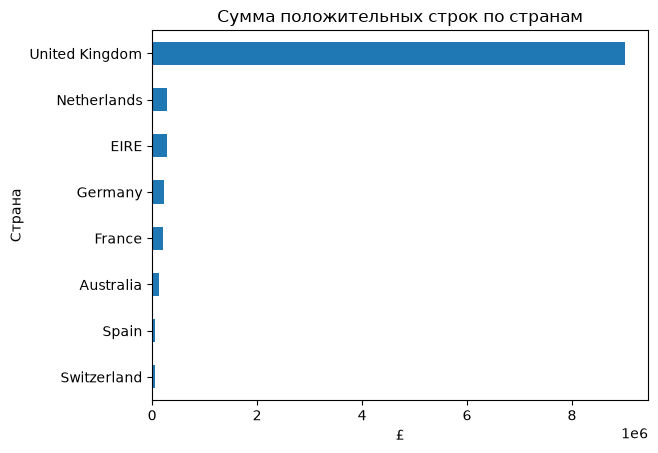

In [33]:
country.set_index("Country")["revenue"].head(8).sort_values().plot.barh(
    title="Сумма положительных строк по странам", xlabel="£", ylabel="Страна")
plt.show()

**Что видим.** На общем графике столбец Великобритании намного длиннее остальных.

**Как думать.** Это верно для суммы **выбранных положительных строк**. Чтобы сравнить другие страны между собой, нужен отдельный график без крупнейшей; в общем выводе её всё равно учитывай.

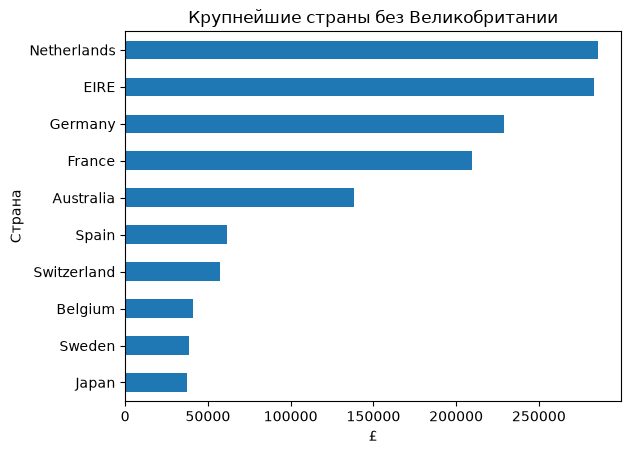

In [34]:
country.set_index("Country")["revenue"].iloc[1:11].sort_values().plot.barh(
    title="Крупнейшие страны без Великобритании", xlabel="£", ylabel="Страна")
plt.show()

**Что видим.** Без Великобритании лучше различимы Нидерланды, Ирландия, Германия и Франция. Нидерланды и Ирландия близки по общей сумме.

**Как думать.** Похожие суммы не означают похожее поведение покупателей. Проверь число счетов и сумму на один счёт: две страны могут прийти к одной сумме разными путями.

Для линии по месяцам можно собрать сумму через `groupby`, затем строить график. Декабрь 2011 исключён: он неполный.

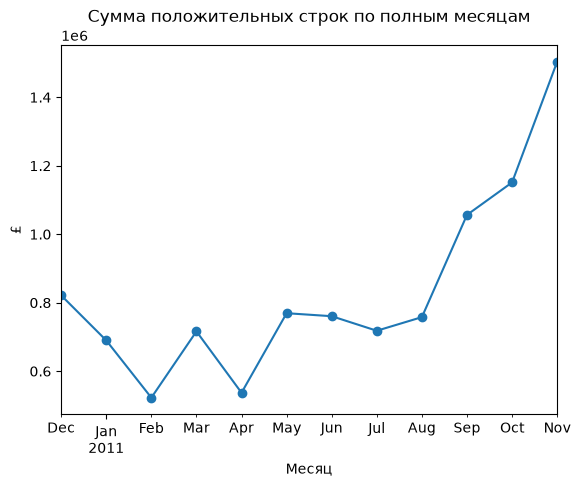

In [35]:
month_check.loc[:"2011-11", "revenue"].plot.line(
    marker="o", title="Сумма положительных строк по полным месяцам",
    xlabel="Месяц", ylabel="£")
plt.show()

**Что видим.** Среди полных месяцев на графике ноябрь 2011 самый высокий. Декабрь 2011 намеренно не показан, так как в файле есть только первые девять дней.

**Как думать.** Линия помогает заметить изменение, но не объясняет его. Проверь, выросло ли число счетов, средний счёт или оба показателя. Не делай вывода о сезонности по одному году.

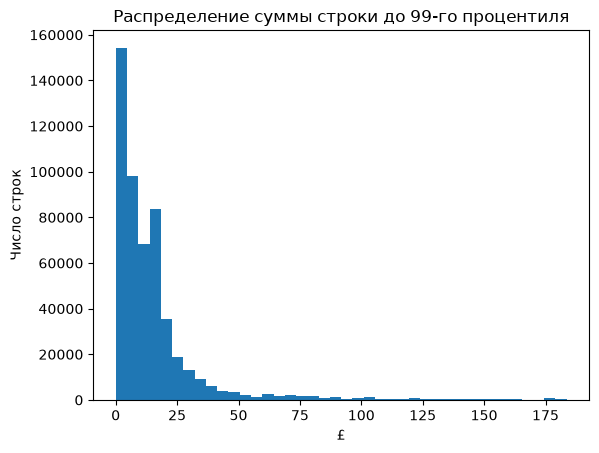

Показано строк: 519646 из 524878 | 99-й процентиль: 183.6


In [36]:
limit = sales["Revenue"].quantile(.99)
sales.loc[sales["Revenue"].le(limit), "Revenue"].plot.hist(
    bins=40, title="Распределение суммы строки до 99-го процентиля", xlabel="£", ylabel="Число строк")
plt.show()
print("Показано строк:", int(sales["Revenue"].le(limit).sum()), "из", len(sales),
      "| 99-й процентиль:", round(limit, 2))

**Что видим.** На рисунке 519 646 из 524 878 строк; верхний 1% скрыт только ради читаемости. 99-й процентиль суммы строки — £183,60. Большинство показанных строк заметно дешевле этого порога.

**Как думать.** Подпиши, какой срез показан. Если убрать большие значения только с графика, нельзя забывать их при подсчёте полной суммы. Сравни среднее с медианой — длинный хвост может сильно поднять среднее.

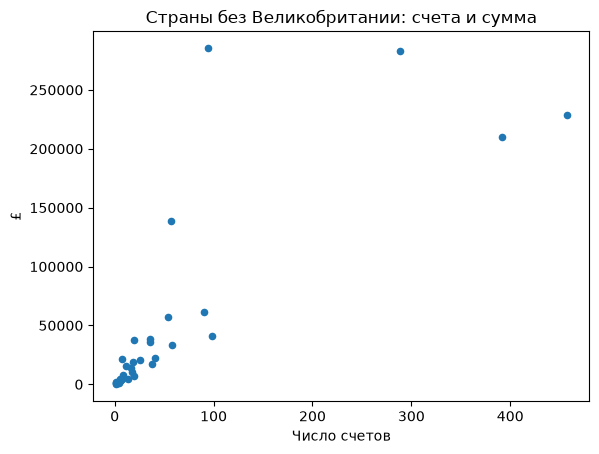

In [37]:
country.iloc[1:].plot.scatter(
    x="orders", y="revenue", title="Страны без Великобритании: счета и сумма",
    xlabel="Число счетов", ylabel="£")
plt.show()

**Что видим.** Обычно у стран с большим числом счетов больше и общая сумма, но точки не ложатся на одну прямую.

**Как думать.** По точечному графику нельзя утверждать, что число счетов *вызывает* высокую сумму. Посчитай сумму на счёт и посмотри страны, которые сильно отличаются от остальных. Проверь, не состоят ли их заказы из крупных оптовых партий.

### Попробуй сам: 5 задач по группировкам и графикам

### 4.1. Страны и доминирование

Для каждой страны посчитай строки, разные счета, известных клиентов, сумму и долю общей суммы. Нарисуй график со всеми странами и второй — без Великобритании. **Проверка:** Великобритания даёт около 84,6% суммы выбранных положительных строк.

**Необязательно — подумай:** большая сумма идёт от большого числа счетов или от большого счёта? Посчитай сумму на счёт хотя бы для нескольких стран.

In [ ]:
# 4.1. Страны и доминирование
# Для автопроверки в ans положите DataFrame по странам (индекс Country по алфавиту): lines, orders, customers (известные ID), revenue, share; расчёт на sales.
ans = None  # замените на вычисленный результат
test_task_N(16, ans)


### 4.2. Время и неполный месяц

Для каждого месяца посчитай сумму и число счетов. Нарисуй линию только по полным месяцам. Затем посчитай среднюю сумму **счёта**, а не строки.

**Необязательно — подумай:** если общая сумма выросла, выросли ли сами счета? Посмотри отдельно число счетов и сумму на счёт. Почему декабрь 2011 должен быть помечен как неполный?

In [ ]:
# 4.2. Время и неполный месяц
# Для автопроверки в ans положите DataFrame по месяцам YYYY-MM: revenue, orders (разные счета), per_order = revenue / orders; расчёт на sales.
ans = None  # замените на вычисленный результат
test_task_N(17, ans)


### 4.3. Товары: штуки против денег

Сделай два топ-10 по `StockCode`: по числу проданных единиц и по сумме. Для нескольких лидеров открой исходные строки с названиями; проверь, бывают ли разные названия у одного кода.

**Необязательно — подумай:** одинаковы ли лидеры? Есть ли в списке `DOTCOM POSTAGE` или другие служебные позиции? Как поменяется список, если вопрос именно об обычных товарах?

In [ ]:
# 4.3. Товары: штуки против денег
# Для автопроверки в ans положите словарь: top_quantity и top_revenue — Series топ-10 StockCode из sales; при равенстве значений сортировка по коду.
ans = None  # замените на вычисленный результат
test_task_N(18, ans)


### 4.4. Концентрация клиентов

Оставь строки с известным `CustomerID`. Посчитай сумму на клиента, медиану, 90-й и 99-й процентили. Найди долю суммы верхнего 1% клиентов и нарисуй гистограмму.

**Необязательно — подумай:** можно ли назвать это долей верхнего 1% *всех* клиентов? Сколько денег не попало в анализ клиентов из-за пустых ID? Сравни ещё верхние 5% с верхним 1%.

In [ ]:
# 4.4. Концентрация клиентов
# Для автопроверки в ans положите словарь: customer_revenue (Series по известным CustomerID), median, p90, p99, top1_share, top5_share, unknown_revenue. Размер топа округлить вверх.
ans = None  # замените на вычисленный результат
test_task_N(19, ans)


### 4.5. Сводная по странам и месяцам

Для пяти крупнейших стран сделай таблицу «месяц × страна» по сумме. Преврати её в длинную таблицу через `melt`. Проверь, что общая сумма до и после совпадает.

**Необязательно — подумай:** выбери два **полных** месяца и сравни доли стран, а не только суммы. Если видишь изменение, что ещё проверишь перед выводом о реальном сдвиге спроса?

In [ ]:
# 4.5. Сводная по странам и месяцам
# Для автопроверки в ans положите словарь: wide (сводная месяц × пять стран с наибольшей revenue), long (melt wide); месяцы и страны по алфавиту, long отсортирован по month/Country.
ans = None  # замените на вычисленный результат
test_task_N(20, ans)


<a id="topic10"></a>
## 5. Соединения и время

`merge` добавляет столбцы по общему ключу. Сначала проверь, уникален ли ключ справа. Если он повторяется, одна строка слева может превратиться в несколько. `validate="many_to_one"` остановит соединение при такой ошибке, а `indicator=True` покажет строки без пары.

Здесь справочник `StockCode → Description` мы получили из того же набора. У товара название может меняться. Если делаешь прогноз на прошлую дату, справочник из будущего использовать нельзя.

In [43]:
product_lookup = (sales.dropna(subset=["Description"])
                  .sort_values("InvoiceDate")
                  .drop_duplicates("StockCode", keep="last")
                  [["StockCode", "Description"]]
                  .rename(columns={"Description": "LatestDescription"}))
joined = sales.head(1000).drop(columns="Description").merge(
    product_lookup, on="StockCode", how="left", validate="many_to_one", indicator=True)
print("До и после merge:", 1000, len(joined))
display(joined["_merge"].value_counts())
display(joined[["StockCode", "LatestDescription"]].head(3))

До и после merge: 1000 1000


_merge
both          1000
left_only        0
right_only       0
Name: count, dtype: int64

,StockCode,LatestDescription
0,85123A,CREAM HANGING HEART T-LIGHT HOLDER
1,71053,WHITE MOROCCAN METAL LANTERN
2,84406B,CREAM CUPID HEARTS COAT HANGER


**Что видим.** В примере `merge` сохранил 1 000 строк; все 1 000 нашли пару. У некоторых кодов новое название отличается от того, что было в ранней строке.

**Как думать.** После каждого соединения сравни число строк до и после и посмотри `_merge`. Если используешь «последнее название», не выдавай его за историческое название товара на дату старого счёта.

### `concat`: сложить таблицы друг под другом

`pd.concat([a, b], ignore_index=True)` добавляет строки `b` после `a`. Проверь, что набор столбцов совпадает; иначе появятся пустые клетки. Если затем считаешь число разных счетов, повторяющийся счёт в двух частях должен учитываться один раз.

In [44]:
part_a = sales.head(2)[["InvoiceNo", "Revenue"]]
part_b = sales.iloc[2:4][["InvoiceNo", "Revenue"]]
together = pd.concat([part_a, part_b], ignore_index=True)
display(together)
print("Строк:", len(together), "| разных счетов:", together["InvoiceNo"].nunique())

,InvoiceNo,Revenue
0,536365,15.30
1,536365,20.34
2,536365,22.00
3,536365,20.34


Строк: 4 | разных счетов: 1


**Что видим.** После `concat` четыре товарные строки, но один и тот же счёт может занимать несколько строк.

**Как думать.** После склейки пересчитай то, что тебе действительно нужно: строки, счета или клиентов.

### Время: прошлое не должно видеть будущее

`resample("D")` собирает строки по дням, `resample("ME")` — по месяцам. `shift(1)` берёт предыдущее значение. Для среднего **за прошлые семь дней** сначала сдвинь ряд на один день, а потом применяй `rolling(7)`.

День без строк может означать «не было записей» — это пока не то же самое, что доказанные нулевые продажи. Декабрь 2011 заканчивается в наборе 9-го числа, поэтому его месячную сумму нельзя напрямую сравнивать с полным ноябрём.

In [45]:
daily = sales.set_index("InvoiceDate")["Revenue"].resample("D").sum(min_count=1)
time_view = pd.DataFrame({"revenue": daily})
time_view["prev_day"] = time_view["revenue"].shift(1)
time_view["prev_7d_mean"] = time_view["revenue"].shift(1).rolling(7, min_periods=3).mean()
display(time_view.head(10).round(2))
monthly = sales.set_index("InvoiceDate")["Revenue"].resample("ME").sum()
print("Максимальный полный месяц до декабря 2011:")
display(monthly.loc[:"2011-11-30"].nlargest(3).round(2))

,revenue,prev_day,prev_7d_mean
InvoiceDate,,,
2010-12-01,58776.79,NaN,NaN
2010-12-02,47629.42,58776.79,NaN
2010-12-03,46898.63,47629.42,NaN
2010-12-04,NaN,46898.63,51101.61
2010-12-05,31364.63,NaN,51101.61
2010-12-06,54624.15,31364.63,46167.37
2010-12-07,99553.85,54624.15,47858.72
2010-12-08,45235.36,99553.85,56474.58
2010-12-09,53548.19,45235.36,54217.67


Максимальный полный месяц до декабря 2011:


InvoiceDate
2011-11-30    1503866.78
2011-10-31    1151263.73
2011-09-30    1056435.19
Freq: -1ME, Name: Revenue, dtype: float64

**Что видим.** 4 декабря в дневном ряду нет записанной суммы (`NaN`). Из-за этого лаг следующего дня тоже пустой. Ноябрь 2011 — самый большой из показанных полных месяцев.

**Как думать.** Реши, означает ли отсутствие строк ноль или неизвестное значение: для разных задач ответ разный. Рост месячной суммы ещё не объясняет причину; сравни число счетов и сумму на счёт. Для прогноза используй только прошлые дни.

### Накопленная сумма и сохранение результата

`.cumsum()` считает накопленную сумму. Она **включает текущую строку**. Если нужен признак для предсказания сегодняшнего дня, сначала сдвинь ряд на день: `.shift(1)`. Таблицу можно сохранить через `.to_csv(..., index=False)`, затем прочитать через `pd.read_csv(...)`. После чтения проверь типы и ключевые суммы.

In [46]:
example_values = pd.Series([5, 10, 2], index=["день 1", "день 2", "день 3"])
display(pd.DataFrame({"сегодня": example_values,
                      "накоплено включая сегодня": example_values.cumsum(),
                      "накоплено до сегодня": example_values.cumsum().shift(1)}))
summary_path = cache_dir / "country_example.csv"
country.head(3).to_csv(summary_path, index=False)
loaded_summary = pd.read_csv(summary_path)
print("Сохранили и прочитали стран:", len(loaded_summary))
print("Сумма сохранилась:", bool(np.isclose(country.head(3)["revenue"].sum(),
                                          loaded_summary["revenue"].sum())))

,сегодня,накоплено включая сегодня,накоплено до сегодня
день 1,5,5,NaN
день 2,10,15,5.0
день 3,2,17,15.0


Сохранили и прочитали стран: 3
Сумма сохранилась: True


**Что видим.** В накопленном значении для третьего дня `17` учтён сам третий день; в колонке «до сегодня» — только `15`. После CSV числа сохранились, но типы надо проверять при каждом новом чтении.

**Как думать.** Для прогноза данные из дня, который предсказываешь, использовать нельзя. После сохранения проверь, что ответ не изменился.

### Попробуй сам: 5 задач по соединениям и времени

### 5.1. Справочник товаров и merge

Из `retail` сделай справочник «код → последнее непустое название». Соедини его с 10 000 строками `sales` через `merge(..., validate="many_to_one", indicator=True)`. Сравни длину до и после и число строк без пары.

**Необязательно — подумай:** почему надо проверять уникальность кода справа? Может ли «последнее название» неверно описывать старый счёт?

In [ ]:
# 5.1. Справочник товаров и merge
# Для автопроверки в ans положите словарь: lookup (StockCode, LatestDescription; последнее непустое название по дате, стабильная сортировка), joined (StockCode, LatestDescription, _merge для sales.head(10000)).
ans = None  # замените на вычисленный результат
test_task_N(21, ans)


### 5.2. Взрыв строк

Построй маленький учебный пример размножения строк: возьми 1000 строк `sales`, а справа оставь не больше двух строк на `StockCode` из `retail`. Соедини и сравни число строк. Проверь `validate="many_to_one"`, затем оставь один ряд на код и соедини снова.

**Необязательно — подумай:** какой код добавил больше всего лишних строк? Что будет с суммой после такого неправильного соединения?

In [ ]:
# 5.2. Взрыв строк
# Для автопроверки в ans положите словарь: exploded_rows, restored_rows, largest_extra_code, exploded_revenue, restored_revenue. Справа retail.groupby("StockCode", sort=False).head(2)[["StockCode", "Description"]]; слева sales.head(1000).
ans = None  # замените на вычисленный результат
test_task_N(22, ans)


### 5.3. Новые коды товаров

Раздели положительные строки по дате: до 1 сентября 2011 и после. Найди коды позднего периода, которых не было в раннем, через `isin` и через `merge(..., indicator=True)`; сравни списки. Посчитай их долю в поздней сумме.

**Необязательно — подумай:** отсутствие кода в раннем срезе точно означает «новый товар»? Какие ещё объяснения возможны?

In [ ]:
# 5.3. Новые коды товаров
# Для автопроверки в ans положите словарь: new_codes (отсортированный список StockCode после 2011-09-01, которых не было раньше) и late_revenue_share; расчёт на sales.
ans = None  # замените на вычисленный результат
test_task_N(23, ans)


### 5.4. Лаги без будущего

Сделай дневной ряд суммы. Добавь вчерашнее значение, среднее семи **прошлых** дней и накопленную сумму до текущего дня. Выведи первые 10 строк для проверки и нарисуй две линии.

**Необязательно — подумай:** что делать с днём без записей — считать нулём или оставить неизвестным? Почему текущее значение не должно попасть в признак для прогноза этого дня?

In [ ]:
# 5.4. Лаги без будущего
# Для автопроверки в ans положите DataFrame дневного ряда из sales: revenue, prev_day, prev_7d_mean (shift(1).rolling(7, min_periods=3).mean()), cumulative_before (cumsum().shift(1)); пропуски дней оставить.
ans = None  # замените на вычисленный результат
test_task_N(24, ans)


### 5.5. Финальный мини-отчёт

Собери таблицу показателей: качество данных, страны и товары, изменение по месяцам. Добавь три простых графика разных видов. Необязательно: сформулируй три вывода с числами, срезами и ограничениями.

**Необязательно — подумай:** проверь, что сравниваешь одинаковые величины и полные периоды. Сохрани таблицу через `to_csv(..., index=False)`, прочитай обратно и проверь типы и сумму.

In [ ]:
# 5.5. Финальный мини-отчёт
# Для автопроверки в ans положите словарь: raw_rows, duplicates, top_country, top_product, best_full_month (до декабря 2011), positive_revenue. Это числовая часть отчёта; текстовый вывод не требуется.
ans = None  # замените на вычисленный результат
test_task_N(25, ans)


<a id="cheat"></a>
## Шпаргалка: коротко о главном

### 1. Как быстро разобраться в таблице

| Вопрос | Команда | Что заметить |
|---|---|---|
| Что означает строка? | `df.head()` | Товарная строка, счёт и клиент — разные единицы анализа. |
| Каков размер? | `df.shape` | `len(df)` считает строки, а не разные заказы. |
| Верны ли типы? | `df.dtypes` | Коды и ID оставляй строками/ID; дату — датой. |
| Где неизвестные значения? | `df.isna().sum()` и `.mean()` | Число и доля пропусков; у каких групп их больше? |
| Есть ли повторы? | `df.duplicated().sum()` | Полный повтор отличается от повторного товара в счёте. |
| Какие значения обычные? | `df.describe()` и `.quantile([.5,.9,.99])` | Медиана и хвост надёжнее одного среднего. |
| Сколько разных объектов? | `df["InvoiceNo"].nunique()` | Выбери нужный ключ: счёт, товар или клиент. |

### 2. Как получить ответ

| Нужно | Команда | Проверка смысла |
|---|---|---|
| Выбрать строки | `df.loc[(cond1) & (cond2)]` | Пропуски и пересечение условий. |
| Выбрать по номеру/метке | `.iloc[0]` / `.loc[метка]` | После фильтра метки могут быть «дырявыми». |
| Исправить часть строк | `df.loc[mask, "x"] = value` | Работай с копией; цепочка скобок не меняет исходную таблицу. |
| Посчитать по группам | `groupby("Country").agg(...)` | Одно значение на группу; сравни число строк и счетов. |
| Добавить значение каждой строке | `groupby(...)["x"].transform("mean")` | Длина результата должна равняться числу строк. |
| Сравнить две группы во времени | `pivot_table(index="month", columns="Country", values="Revenue", aggfunc="sum")` | Пустая клетка не обязательно ноль. |
| Соединить таблицы | `merge(..., validate="many_to_one", indicator=True)` | Длина, уникальность правого ключа и строки без пары. |
| Изучить прошлое | `shift(1).rolling(7).mean()` | Для прогноза текущий день не должен попасть в признак. |
| Сделать график | `.plot.bar()`, `.plot.line()`, `.plot.hist()` | Название, единицы, срез и неполные периоды. |

### 3. Если увидел неожиданное

| Видишь | Сначала проверь | Осторожный вывод |
|---|---|---|
| Большую сумму | Число счетов и сумму на счёт | «Группа даёт больше денег», но причина ещё не ясна. |
| Очень большое значение | Сами строки, единицы, название позиции | Это может быть опт, услуга или ошибка. |
| Пустой ID | Где и как часто он пропущен | Неизвестных клиентов нельзя склеивать в одного. |
| `NaN` после соединения | Совпали ли ключи | Причина может быть в разных наборах ключей. |
| Внезапное падение на графике | Полон ли период, не изменился ли срез | Не называй это спадом без проверки. |
| Сильную «связь» двух чисел | Размер групп, выбросы и третьи факторы | Связь на графике ещё не доказывает причину. |

**Шаблон вывода в одну строку:** «В срезе ___ показатель ___ равен ___; это похоже на ___, но для проверки нужны ___».

### Пять проверок перед сдачей решения

1. Скажи, **что означает строка** и какая единица анализа нужна для вопроса.
2. Укажи **срез**: сырые строки `retail`, положительные `sales`, строки только с известным клиентом или другой.
3. Сравни итог с **числом объектов** и, если нужно, со средним на объект.
4. Проверь **пропуски, дубли, выбросы и неполные периоды**, которые могут изменить вывод.
5. Подпиши график и сформулируй вывод без выдуманной причинности.

<a id="complex"></a>
## 6. Комплексные задачи

Ниже пять самостоятельных задач в стиле соревнования: описание системы, файлы и формат результата. Данные лежат рядом с notebook в папке `complex_data`; интернет для них не нужен. В каждой задаче передай **готовый DataFrame** как `ans` в `test_task_N(номер, ans)`. Сохраняй указанный порядок столбцов и строк. Исходные CSV могут быть перемешаны по времени и идентификаторам.


In [ ]:
complex_dir = Path("programming/class11: train pandas/complex_data")
if not complex_dir.is_dir():
    complex_dir = Path("complex_data")
print("Данные комплексных задач:", complex_dir.resolve())


### 26. Журнал устройств

Сервис следит за устройствами. В `device_events.csv` записаны `event_id`, `device_id`, `timestamp` и `event`. Событие `error` переводит устройство в состояние «нуждается в проверке», `reset` восстанавливает работу, а `heartbeat` ничего не меняет. В `device_requests.csv` хранятся `request_id`, `device_id` и `timestamp` запросов состояния. Изначально каждое устройство работает. На момент запроса учитываются события **включительно** до его времени; если у событий одинаковое время, их порядок задаёт `event_id`. Строки файлов заранее не отсортированы.

Для каждого запроса верни состояние устройства. Итоговый DataFrame должен иметь ровно столбцы `request_id`, `state`, быть отсортирован по `request_id` и иметь обычный индекс 0, 1, 2, ... . `state` равно 0, если устройство работает, и 1, если нуждается в проверке.


In [ ]:
device_events = pd.read_csv(complex_dir / "device_events.csv", parse_dates=["timestamp"])
device_requests = pd.read_csv(complex_dir / "device_requests.csv", parse_dates=["timestamp"])

# В ans положите DataFrame со столбцами request_id, state в порядке request_id.
ans = None  # замените на ваш результат
test_task_N(26, ans)


### 27. Продажи после частичных возвратов

У магазина три файла. `orders.csv`: `order_id`, `customer_id`, `created_at`, `status` (`paid` или `cancelled`). `order_items.csv`: `item_id`, `order_id`, `product_id`, `quantity`, `unit_price`, `discount_pct`. `item_returns.csv`: `return_id`, `item_id`, `quantity`, `returned_at`. Одну позицию могут возвращать несколькими записями. Возврат сокращает число оставшихся единиц этой позиции; стоимость возвращённых единиц считается по той же цене **после скидки**, что и исходная продажа. Учитываются возвраты раньше `2026-11-01 00:00:00`. Отменённые заказы дают ноль независимо от товарных строк.

Подготовь отчёт **по всем заказам** с итогом на эту дату. DataFrame: `order_id`, `net_units`, `net_revenue`, сортировка по `order_id`, индекс 0, 1, 2, ... . `net_units` — число оставшихся у покупателя единиц, `net_revenue` — их стоимость с учётом скидки. Денежная единица условная.


In [ ]:
orders = pd.read_csv(complex_dir / "orders.csv", parse_dates=["created_at"])
order_items = pd.read_csv(complex_dir / "order_items.csv")
item_returns = pd.read_csv(complex_dir / "item_returns.csv", parse_dates=["returned_at"])

# В ans положите DataFrame: order_id, net_units, net_revenue; все заказы по order_id.
ans = None  # замените на ваш результат
test_task_N(27, ans)


### 28. Книги, продления и просрочка

Библиотека хранит `loans.csv` (`loan_id`, `reader_id`, `book_id`, `borrowed_at`, `due_at`) и `loan_events.csv` (`action_id`, `loan_id`, `timestamp`, `action`, `new_due_at`). Действие `renew` заменяет срок сдачи на `new_due_at`; `return` завершает выдачу. После первого возврата события этой выдачи ничего не меняют. Состояние нужно на начало `2026-11-01`: более поздние события не учитывать. При одинаковом времени порядок действий задаёт `action_id`.

Верни DataFrame по каждой выдаче: `loan_id`, `final_due`, `returned_at`, `overdue_days`, `state`. `final_due` — дата срока в виде строки `YYYY-MM-DD`; `returned_at` — время первого возврата или `NaT`; `state` — `returned` или `open`. Просрочку считай в **календарных днях** от `final_due` до даты возврата, а для открытой выдачи — до `2026-10-31` включительно; отрицательная просрочка превращается в 0. Строки отсортируй по `loan_id`, индекс сбрось.


In [ ]:
loans = pd.read_csv(complex_dir / "loans.csv", parse_dates=["borrowed_at", "due_at"])
loan_events = pd.read_csv(complex_dir / "loan_events.csv", parse_dates=["timestamp", "new_due_at"])

# В ans положите DataFrame: loan_id, final_due, returned_at, overdue_days, state.
ans = None  # замените на ваш результат
test_task_N(28, ans)


### 29. Остаток на момент запроса

`opening_stock.csv` задаёт начальное `quantity` для каждой пары `warehouse`, `sku` на `2026-10-20 08:00:00`. В `stock_movements.csv` находятся `movement_id`, `warehouse`, `sku`, `timestamp`, `delta`: положительное `delta` добавляет товар, отрицательное списывает. `stock_requests.csv` содержит `request_id`, `warehouse`, `sku`, `timestamp`, `quantity` — запросы на проверку наличия. Сами запросы товар **не резервируют и не списывают**. При расчёте остатка учитывай все движения с временем не позже времени запроса.

Для каждого запроса верни DataFrame с полями `request_id`, `available`, `can_fulfill`. `available` — остаток на момент запроса; `can_fulfill` — 1, если товара хватает на указанное количество, иначе 0. Строки отсортируй по `request_id`, индекс сбрось.


In [ ]:
opening_stock = pd.read_csv(complex_dir / "opening_stock.csv")
stock_movements = pd.read_csv(complex_dir / "stock_movements.csv", parse_dates=["timestamp"])
stock_requests = pd.read_csv(complex_dir / "stock_requests.csv", parse_dates=["timestamp"])

# В ans положите DataFrame: request_id, available, can_fulfill для каждого запроса.
ans = None  # замените на ваш результат
test_task_N(29, ans)


### 30. Ответ службы поддержки

`tickets.csv` содержит `ticket_id`, `priority`, `opened_at`. В `ticket_events.csv` записаны `event_id`, `ticket_id`, `timestamp`, `event`: `agent_reply`, `customer_message`, `close`, `reopen`. Нужно состояние на начало `2026-11-03`, события после этого момента не учитывать. Первый `agent_reply` определяет время ответа в минутах от открытия. Предел для `high` — 60 минут, `normal` — 240, `low` — 1440. Отсутствие ответа означает, что предел не выполнен. `close` и `reopen` меняют текущее состояние заявки; изначально она открыта. При совпадении времени порядок событий задаёт `event_id`.

Итог для **каждой** заявки — DataFrame со столбцами `ticket_id`, `first_reply_minutes`, `state`, `sla_met`. Если ответа нет, `first_reply_minutes` должен быть пропуском; `state` принимает `open` или `closed`; `sla_met` равно 1 при ответе в пределах нормы и 0 иначе. Строки отсортируй по `ticket_id`, индекс сбрось.


In [ ]:
tickets = pd.read_csv(complex_dir / "tickets.csv", parse_dates=["opened_at"])
ticket_events = pd.read_csv(complex_dir / "ticket_events.csv", parse_dates=["timestamp"])

# В ans положите DataFrame: ticket_id, first_reply_minutes, state, sla_met.
ans = None  # замените на ваш результат
test_task_N(30, ans)
